<a href="https://colab.research.google.com/github/Lourdes-Churacutipa/Repositorio-de-lourdes/blob/main/Lab7_4_KNN_Peru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Vecinos Más Cercanos (KNN)
## Ciencia de Datos Ambientales – Aplicado al Perú

**Duración:** 75 minutos

Referencia: [documentación de KNN en scikit-learn](https://scikit-learn.org/stable/modules/neighbors.html)

---

### Objetivos de aprendizaje

1. Explicar el algoritmo KNN para clasificación y regresión.
2. Calcular distancias entre puntos y usarlas para encontrar vecinos más cercanos.
3. Describir cómo la elección de $k$ afecta el tradeoff sesgo-varianza.
4. Explicar por qué el escalado de características es crítico para KNN.
5. Entrenar, evaluar y ajustar un modelo KNN en `scikit-learn`.
6. Aplicar KNN para predecir caudales de ríos amazónicos desde datos meteorológicos.

## 1. La Intuición: Eres Similar a Tus Vecinos

La filosofía detrás de KNN es simple y ecológica:

- **Organismos en ambientes similares tienden a ser similares** — por eso las parcelas cercanas en un gradiente ambiental comparten especies.
- **Un píxel Landsat con valores espectrales similares a los del bosque amazónico probablemente también es bosque amazónico.**
- **Si los 5 días meteorológicos más similares a hoy todos tuvieron alto caudal en el río Ucayali, es probable que hoy también haya alto caudal.**

KNN formaliza esto: para clasificar o predecir un nuevo punto, busca los **$k$ vecinos más cercanos** en el conjunto de entrenamiento y usa sus etiquetas o valores.

## 2. ¿Cómo Funciona KNN?

### El algoritmo

1. **Almacenar** todo el dataset de entrenamiento (KNN no tiene fase de entrenamiento real).
2. Para un nuevo punto $\mathbf{x}_{nuevo}$, **calcular la distancia** a cada punto de entrenamiento.
3. **Encontrar los $k$ más cercanos** (los $k$ vecinos más próximos).
4. **Para clasificación:** asignar la clase más común entre los $k$ vecinos (voto mayoritario). **Para regresión:** calcular la media de los valores objetivo de los $k$ vecinos.

### Métrica de distancia

La más común: **distancia Euclídea**:

$$d(\mathbf{x}, \mathbf{x}') = \sqrt{\sum_{j=1}^{M} (x_j - x_j')^2}$$

Otras opciones incluyen la distancia de Manhattan ($L_1$), la distancia de Minkowski y la similitud del coseno.

> **Importante:** Como KNN depende de distancias, **las características con mayor magnitud dominan el cálculo**. Por eso el escalado es esencial.

## 3. Construyendo KNN desde cero

Implementemos KNN manualmente para asegurarnos de comprender cada paso antes de usar `scikit-learn`.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from matplotlib.patches import Circle

# Implementación manual de KNN para demostración
np.random.seed(42)
X_demo = np.random.rand(20, 2) * 10
y_demo = np.random.choice([0, 1], size=20)  # 0=bosque, 1=no-bosque

punto_consulta = np.array([5, 5])
k = 5

# Calcular distancias euclídeas
distancias = np.sqrt(np.sum((X_demo - punto_consulta)**2, axis=1))
idx_vecinos = np.argsort(distancias)[:k]
etiquetas_vecinos = y_demo[idx_vecinos]

voto = Counter(etiquetas_vecinos)
clase_predicha = voto.most_common(1)[0][0]

print(f"Punto de consulta: {punto_consulta}")
print(f"k = {k}")
print(f"Distancias a vecinos: {distancias[idx_vecinos].round(2)}")
print(f"Etiquetas de vecinos: {etiquetas_vecinos} (0=bosque, 1=no-bosque)")
print(f"Votos: {dict(voto)}")
print(f"Clase predicha: {'Bosque' if clase_predicha == 0 else 'No-Bosque'}")

Punto de consulta: [5 5]
k = 5
Distancias a vecinos: [1.94 1.97 2.2  2.31 2.47]
Etiquetas de vecinos: [0 1 1 0 1] (0=bosque, 1=no-bosque)
Votos: {np.int64(0): 2, np.int64(1): 3}
Clase predicha: No-Bosque


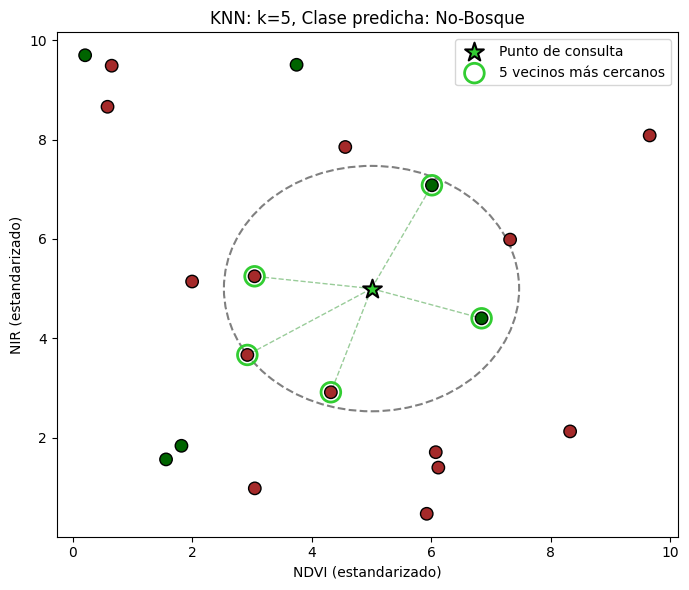

In [ ]:
# Visualización
fig, ax = plt.subplots(figsize=(7, 6))

# Puntos de entrenamiento
colores = ['darkgreen' if etiq == 0 else 'brown' for etiq in y_demo]
ax.scatter(X_demo[:, 0], X_demo[:, 1], c=colores, s=80, edgecolors='k', zorder=3)

# Punto de consulta
ax.scatter(*punto_consulta, c='limegreen', s=200, marker='*',
           edgecolors='k', linewidths=1.5, zorder=4, label='Punto de consulta')

# Círculo que muestra la distancia al vecino más lejano entre los k vecinos
radio = distancias[idx_vecinos[-1]]
circulo = Circle(punto_consulta, radio, fill=False, linestyle='--',
                 edgecolor='gray', linewidth=1.5)
ax.add_patch(circulo)
ax.scatter(X_demo[idx_vecinos, 0], X_demo[idx_vecinos, 1],
           s=200, facecolors='none', edgecolors='limegreen', linewidths=2, zorder=3,
           label=f'{k} vecinos más cercanos')

for idx in idx_vecinos:
    ax.plot([punto_consulta[0], X_demo[idx, 0]],
            [punto_consulta[1], X_demo[idx, 1]], 'g--', alpha=0.4, linewidth=1)

ax.set_xlabel('NDVI (estandarizado)')
ax.set_ylabel('NIR (estandarizado)')
ax.set_title(f'KNN: k={k}, Clase predicha: {"Bosque" if clase_predicha==0 else "No-Bosque"}')
ax.legend()
plt.tight_layout()
plt.show()

La estrella verde representa el punto de consulta. El círculo discontinuo encierra a sus 5 vecinos más cercanos. La clase mayoritaria entre esos vecinos se convierte en la predicción.

## 4. Clasificación KNN con `scikit-learn`

Primero, usemos el `KNeighborsClassifier` de `scikit-learn` con datos sintéticos y, después, con el conjunto de datos Iris.

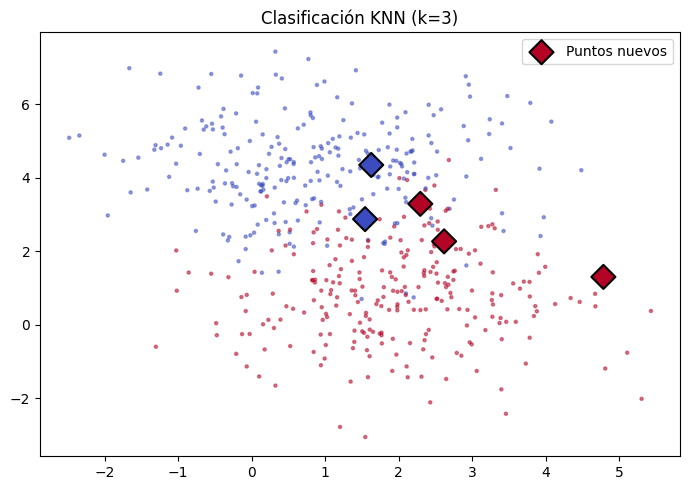

Predicciones para los puntos nuevos: [1 1 0 0 1]


In [ ]:
from sklearn.datasets import make_blobs
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import numpy as np

# ── Conjunto de datos sintético de dos clases ──
X, y = make_blobs(n_samples=500, centers=2, cluster_std=1.3, random_state=0)

# Algunos puntos nuevos para clasificar
rng = np.random.RandomState(0)
X_new = [-1, -1] + [6, 6] * rng.rand(5, 2)

# ── Ajuste de KNN ──
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X, y)
y_pred_new = knn.predict(X_new)

# ── Gráfico ──
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=5, alpha=0.5)
ax.scatter(X_new[:, 0], X_new[:, 1], c=y_pred_new, cmap='coolwarm',
           s=150, edgecolors='k', linewidths=1.5, marker='D',
           label='Puntos nuevos')
ax.set_title('Clasificación KNN (k=3)')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Predicciones para los puntos nuevos: {y_pred_new}")

## 5. KNN para Regresión: Predecir Caudal de Ríos

El algoritmo KNN no solo sirve para clasificación, sino también para regresión. En lugar de una votación mayoritaria, la predicción se basa en la **media de los valores objetivo de los $k$ vecinos**:

$$
\hat{y} = \frac{1}{k} \sum_{i \in \mathcal{N}_k(\mathbf{x})} y_i
$$

donde $\mathcal{N}_k(\mathbf{x})$ es el conjunto de $k$ vecinos más cercanos de $\mathbf{x}$.

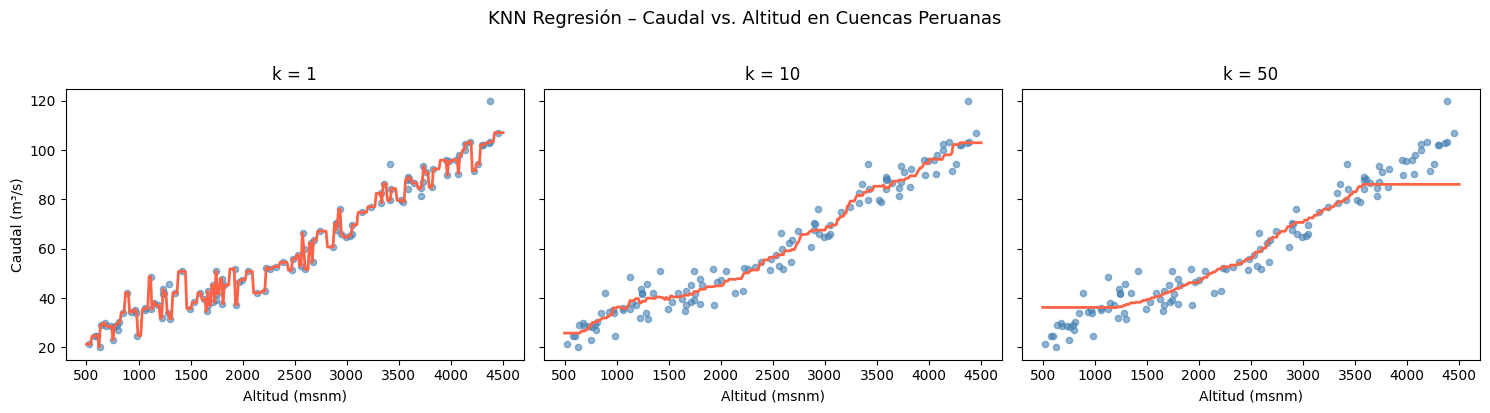

k=1: sobreajuste – la curva sigue cada punto de datos
k=10: buen equilibrio – captura la tendencia general
k=50: subajuste – demasiado suave, pierde variaciones locales


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# Curva hipsométrica: caudal vs. altitud de cuencas peruanas
np.random.seed(42)
n = 120
altitud = np.sort(np.random.uniform(500, 4500, n))  # msnm

# Relación tipo: cuencas altoandinas tienen mayor caudal específico por glaciares
caudal_verdadero = 0.02 * altitud + 5 * np.sin(altitud/500) + 10
caudal = caudal_verdadero + np.random.normal(0, 5, n)
caudal = np.maximum(caudal, 0)

X_alt = altitud.reshape(-1, 1)
alt_fino = np.linspace(500, 4500, 300).reshape(-1, 1)

# Comparar distintos k
fig, ejes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, k in zip(ejes, [1, 10, 50]):
    knn_reg = KNeighborsRegressor(n_neighbors=k)
    knn_reg.fit(X_alt, caudal)
    y_fit = knn_reg.predict(alt_fino)

    ax.scatter(altitud, caudal, color='steelblue', s=20, alpha=0.6)
    ax.plot(alt_fino, y_fit, color='tomato', linewidth=2)
    ax.set_title(f'k = {k}')
    ax.set_xlabel('Altitud (msnm)')

ejes[0].set_ylabel('Caudal (m³/s)')
plt.suptitle('KNN Regresión – Caudal vs. Altitud en Cuencas Peruanas', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

print("k=1: sobreajuste – la curva sigue cada punto de datos")
print("k=10: buen equilibrio – captura la tendencia general")
print("k=50: subajuste – demasiado suave, pierde variaciones locales")

Observe la **compensación entre sesgo y varianza** controlada por $k$:

- **$k = 1$**: la predicción es el valor del vecino más cercano. Muy ruidosa (alta varianza, bajo sesgo): la curva sigue cada punto de datos.

- **$k = 10$**: más suave, captura la forma general del pico. Un buen equilibrio.

- **$k = 50$**: muy suave (baja varianza, alto sesgo): la curva está excesivamente suavizada y no alcanza el pico.

Esto es directamente análogo al grado polinómico y al parámetro $C$ en SVM.

## 6. Elegir $k$: El Hiperparámetro Principal

El valor de $k$ controla el tradeoff sesgo-varianza:
- **k=1**: predicción = valor del vecino más cercano → alta varianza, bajo sesgo → sobreajuste
- **k grande**: promedio de muchos vecinos → baja varianza, alto sesgo → subajuste

Usamos validación cruzada para encontrar el mejor $k$.

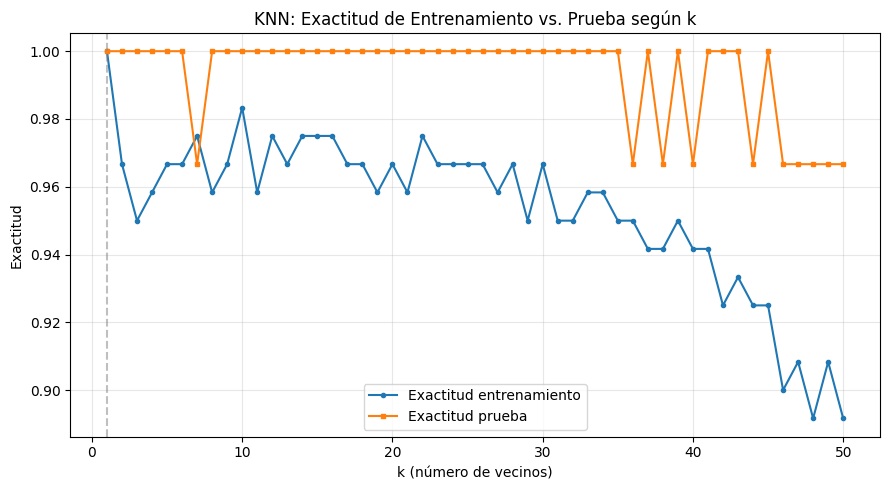

Mejor k en prueba: 1 (exactitud = 100.00%)
Nota: k=1 siempre da 100% en entrenamiento (el vecino más cercano es el mismo punto)


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import load_iris

# Usamos Iris como dataset estándar (aplicable a clasificación de especies)
iris = load_iris()
X, y = iris.data, iris.target
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

rango_k = np.arange(1, 51)
acc_entrena = np.empty(len(rango_k))
acc_prueba  = np.empty(len(rango_k))

for i, k in enumerate(rango_k):
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_tr, y_tr)
    acc_entrena[i] = knn.score(X_tr, y_tr)
    acc_prueba[i]  = knn.score(X_te, y_te)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rango_k, acc_entrena, 'o-', markersize=3, label='Exactitud entrenamiento')
ax.plot(rango_k, acc_prueba, 's-', markersize=3, label='Exactitud prueba')
ax.axvline(rango_k[np.argmax(acc_prueba)], color='gray', linestyle='--', alpha=0.5)
ax.set_xlabel('k (número de vecinos)')
ax.set_ylabel('Exactitud')
ax.set_title('KNN: Exactitud de Entrenamiento vs. Prueba según k')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

mejor_k = rango_k[np.argmax(acc_prueba)]
print(f"Mejor k en prueba: {mejor_k} (exactitud = {acc_prueba.max():.2%})")
print(f"Nota: k=1 siempre da 100% en entrenamiento (el vecino más cercano es el mismo punto)")

Patrones clave a observar:

- **La precisión del entrenamiento con $k=1$ siempre es del 100%**, ya que el vecino más cercano de cualquier punto de entrenamiento es el propio punto.

- **La precisión de la prueba alcanza su máximo con un valor moderado de $k$** y luego disminuye gradualmente a medida que el modelo se vuelve demasiado suave.

- **La diferencia entre la precisión del entrenamiento y la de la prueba con valores bajos de $k$** es un claro indicio de sobreajuste.

En la práctica, utilice la **validación cruzada** en lugar de una única división de entrenamiento/prueba para seleccionar $k$ de forma más robusta.

## 7. Por Qué el Escalado es Crítico en KNN

KNN usa distancias. Si una variable tiene valores en miles (ej. precipitación en mm) y otra en unidades (ej. temperatura en °C), la primera dominará completamente la distancia.

**Demostración:** predecir caudal de la estación de Iquitos desde datos meteorológicos diarios.

### Ejemplo: Predicción de la productividad primaria bruta (PPB) a partir de datos meteorológicos

Utilizaremos datos de [FLUXNET](https://data.fluxnet.org/data/) de la torre de covarianza de remolinos del Bosque de Howland (Maine): mediciones diarias de temperatura del aire (TA), radiación incidente de onda corta (SW_IN) y déficit de presión de vapor (VPD) para predecir la productividad primaria bruta (PPB).

> **Nota:** El archivo de datos se carga desde Google Drive. Si lo ejecuta localmente, ajuste la ruta del archivo según corresponda.

#### Acerca de la red FLUXNET
FLUXNET es una red internacional de redes que conecta redes regionales de científicos del sistema terrestre. Los científicos de FLUXNET utilizan la técnica de covarianza de remolinos para medir el ciclo del carbono, el agua y la energía entre la biosfera y la atmósfera. Estos datos les permiten comprender mejor el funcionamiento de los ecosistemas, la dinámica de los gases traza y la contaminación atmosférica.

La covarianza de remolinos es el método estándar que utilizan los científicos de ecosistemas para medir los flujos de gases traza entre los ecosistemas y la atmósfera. Una ventaja clave de este método es su capacidad para medir los flujos directamente ( in situ) , sin perturbar el ecosistema. En cada sitio se miden los intercambios de gases como dióxido de carbono, metano, agua y otros. Algunos sitios de covarianza de remolinos llevan décadas recopilando datos, lo que permite estudiar cómo cambian los ecosistemas con el tiempo.

Los investigadores que trabajan en redes regionales procesan y analizan datos de covarianza de remolinos y, posteriormente, los ofrecen a través de portales de datos de dichas redes. FLUXNET conecta estas redes regionales, recopilando sus conjuntos de datos para crear productos de datos de covarianza de remolinos procesados ​​y armonizados.

El set de datos fue descargado de [AmeriFlux FLUXNET](https://ameriflux.lbl.gov/data/download-data/)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ── Cargar datos de FLUXNET ──

# OPCION 1: Google Colab con Drive montado
#from google.colab import drive
#drive.mount('/content/drive')
#fname = '/content/drive/MyDrive/AMF_US-Ho1_FLUXNET_FULLSET_DD_1996-2023_3-6.csv'

# OPCION 2: Archivo local (ajusta la ruta)
#fname = "H:/Mi unidad/CDA_posgrado/CDA_share/1_datasets/FLUXNET Shuttle/AMF_US-Ho1_FLUXNET_FULLSET_1996-2023_3-6/AMF_US-Ho1_FLUXNET_FULLSET_DD_1996-2023_3-6.csv"

# OPCION 3: Descargar desde Google Drive con gdown
import gdown
ID = "1QTHZBJTbg_xUorKhLLJ8jlHbowFW9iwP"
fname = gdown.download(f'https://drive.google.com/uc?id={ID}', quiet=False)

Ho = pd.read_csv(fname)
Ho = Ho[["TIMESTAMP", "TA_F", "SW_IN_F", "VPD_F", "GPP_NT_VUT_REF"]]
Ho[Ho <= -9999] = None
Ho = Ho.dropna()

print(f"Conjunto de datos: Bosque de Howland (US-Ho1), datos diarios")
print(f"Muestras: {len(Ho)}")
print(f"Características: TA_F (temperatura del aire, °C), SW_IN_F (radiación de onda corta, W/m²), VPD_F (VPD, hPa)")
print(f"Objetivo: GPP_NT_VUT_REF (productividad primaria bruta, gC/m²/día)")
print()
Ho.describe().round(2)

Downloading...
From: https://drive.google.com/uc?id=1QTHZBJTbg_xUorKhLLJ8jlHbowFW9iwP
To: /content/AMF_US-Ho1_FLUXNET_FULLSET_DD_1996-2023_3-6.csv
100%|██████████| 24.5M/24.5M [00:00<00:00, 188MB/s]


Conjunto de datos: Bosque de Howland (US-Ho1), datos diarios
Muestras: 9497
Características: TA_F (temperatura del aire, °C), SW_IN_F (radiación de onda corta, W/m²), VPD_F (VPD, hPa)
Objetivo: GPP_NT_VUT_REF (productividad primaria bruta, gC/m²/día)



,TIMESTAMP,TA_F,SW_IN_F,VPD_F,GPP_NT_VUT_REF
count,9497.00,9497.00,9497.00,9497.00,9497.00
mean,20085664.31,7.04,100.56,4.03,2.65
std,75008.70,9.43,74.17,2.02,3.56
min,19960101.00,-22.50,2.15,0.17,-0.97
25%,20020702.00,0.32,38.34,2.76,-0.27
50%,20081231.00,7.33,87.62,3.48,0.97
75%,20150702.00,14.48,142.33,4.83,5.33
max,20211231.00,29.40,389.47,21.25,13.56


Observe las magnitudes de las características:

- Temperatura (TA_F): aproximadamente de -20 a 25 °C
- Radiación de onda corta (SW_IN_F): de 0 a ~350 W/m²
- Presión de vapor (VPD): de 0 a ~15 hPa

Los valores de SW_IN_F son aproximadamente 20 veces mayores que los de VPD. Si ejecutamos KNN sin escalado, las distancias estarán dominadas por SW_IN_F.

In [ ]:
Ho

,TIMESTAMP,TA_F,SW_IN_F,VPD_F,GPP_NT_VUT_REF
0,19960101,4.033,10.244,2.641,-0.642700
1,19960102,-10.566,21.061,2.737,-0.418027
2,19960103,-16.561,31.756,2.688,-0.385695
3,19960104,-14.412,12.453,3.021,-0.837074
4,19960105,-18.341,4.658,2.391,-0.508863
...,...,...,...,...,...
9492,20211227,6.021,84.885,2.670,0.956758
9493,20211228,7.858,13.357,2.572,0.911970
9494,20211229,7.056,39.833,2.617,1.018230
9495,20211230,4.677,15.409,2.590,0.717121


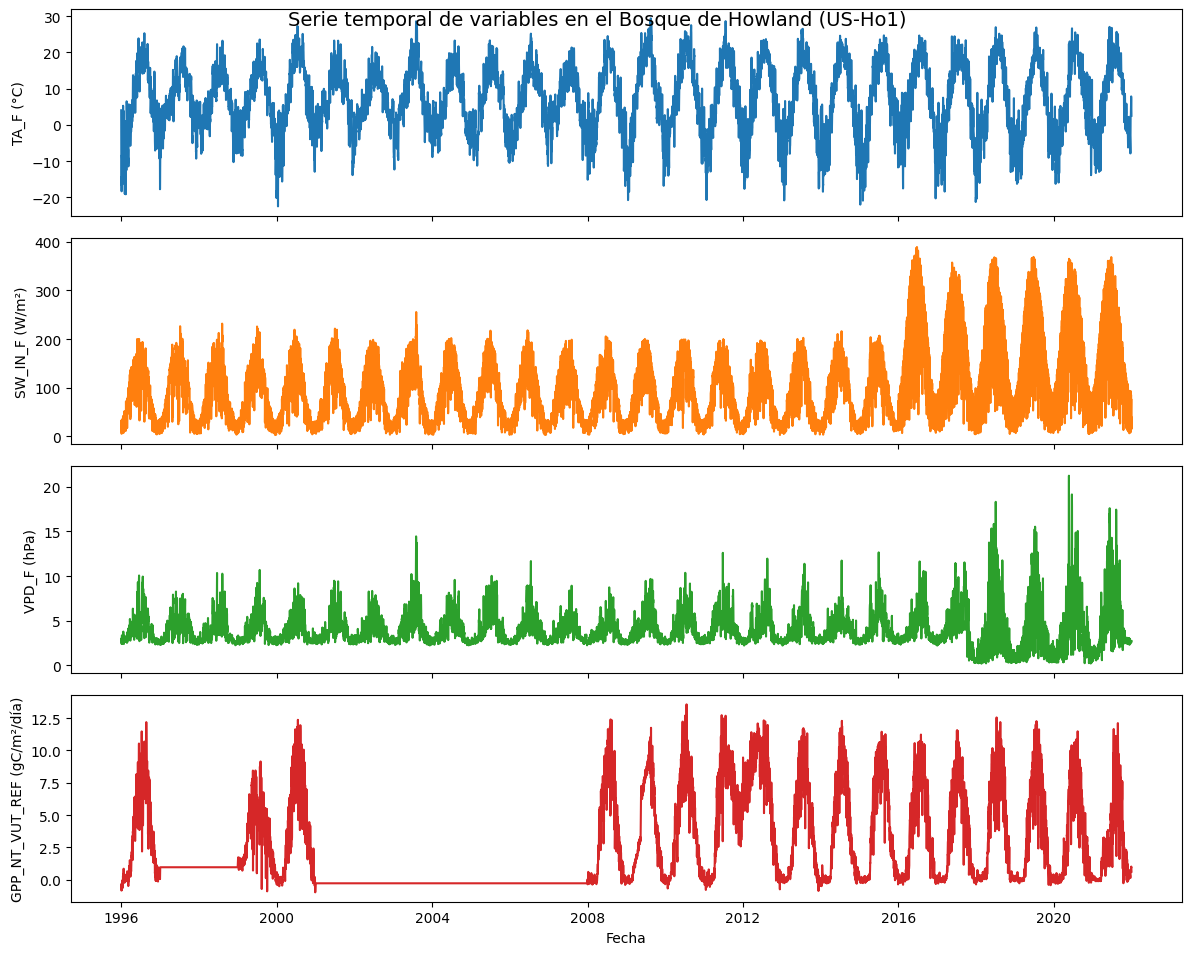

In [ ]:
# Poner TIMESTAMP como índice y convertir a formato datetime diario
Ho["TIMESTAMP"] = pd.to_datetime(Ho["TIMESTAMP"], format="%Y%m%d")
Ho.set_index("TIMESTAMP", inplace=True)

# Ploteamos las series temporales
fig, ax = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
ax[0].plot(Ho.index, Ho["TA_F"], color='tab:blue')
ax[0].set_ylabel('TA_F (°C)')
ax[1].plot(Ho.index, Ho["SW_IN_F"], color='tab:orange')
ax[1].set_ylabel('SW_IN_F (W/m²)')
ax[2].plot(Ho.index, Ho["VPD_F"], color='tab:green')
ax[2].set_ylabel('VPD_F (hPa)')
ax[3].plot(Ho.index, Ho["GPP_NT_VUT_REF"], color='tab:red')
ax[3].set_ylabel('GPP_NT_VUT_REF (gC/m²/día)')
ax[3].set_xlabel('Fecha')
plt.suptitle('Serie temporal de variables en el Bosque de Howland (US-Ho1)', fontsize=14, y=0.95)
plt.tight_layout()
plt.show()

In [ ]:
# Filtrar de 2008 hasta 2016
Ho = Ho[Ho.index >= '2008-01-01'].copy()
Ho = Ho[Ho.index < '2017-01-01'].copy()

array([<Axes: xlabel='TIMESTAMP'>, <Axes: xlabel='TIMESTAMP'>,
       <Axes: xlabel='TIMESTAMP'>], dtype=object)

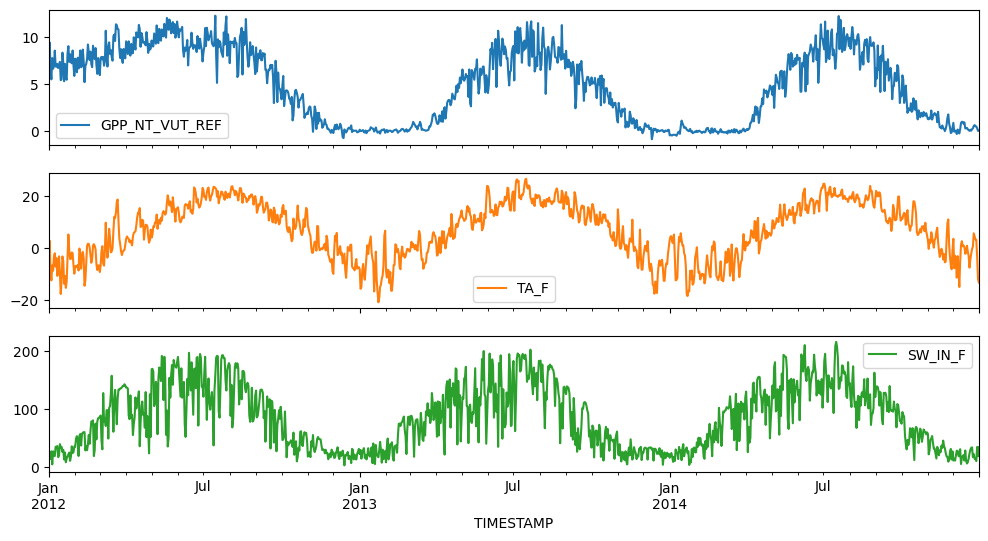

In [ ]:
Ho['2012':'2014'][['GPP_NT_VUT_REF', 'TA_F', 'SW_IN_F']].plot(subplots=True, figsize=(12,6))


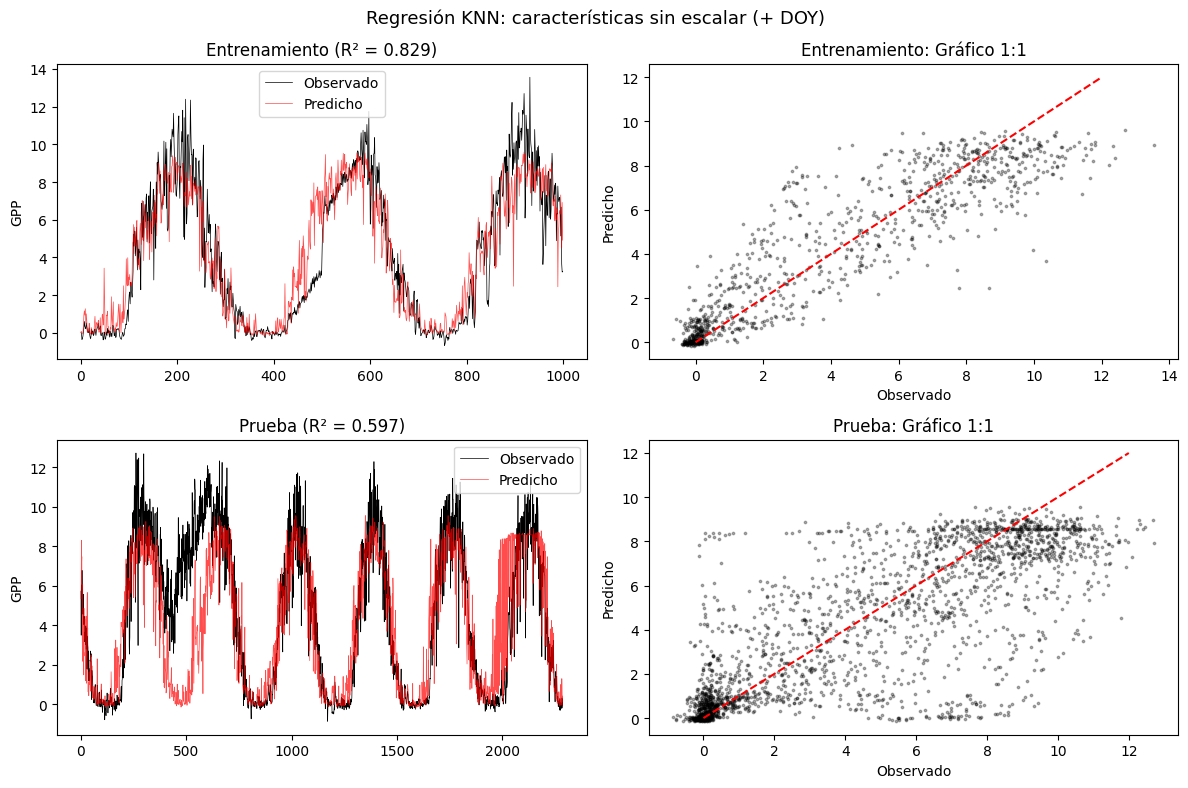

Train R²: 0.829
Test  R²: 0.597

Nota: sin escalado, DOY (1–365) y SW_IN (0–350) dominan las distancias;
TA y VPD contribuyen poco por su menor magnitud.


In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import r2_score
import numpy as np

# Agregar día del año — captura el ciclo estacional de GPP
Ho["DOY"] = Ho.index.dayofyear
Ho["DOY_sin"] = np.sin(2 * np.pi * Ho.index.dayofyear / 365)
Ho["DOY_cos"] = np.cos(2 * np.pi * Ho.index.dayofyear / 365)
Ho["YEAR"] = Ho.index.year

X = Ho[["TA_F", "SW_IN_F", "VPD_F"]].values
#X = Ho[["TA_F", "SW_IN_F", "VPD_F", "DOY"]].values
#X = Ho[["TA_F", "SW_IN_F", "VPD_F", "DOY_sin", "DOY_cos", "YEAR"]].values

y = Ho["GPP_NT_VUT_REF"].values

# División cronológica (primeros 2000 días para entrenamiento)
train_len = 1000
X_train, X_test = X[:train_len], X[train_len:]
y_train, y_test = y[:train_len], y[train_len:]

# KNN sin escalado
knn_raw = KNeighborsRegressor(n_neighbors=20)
knn_raw.fit(X_train, y_train)
y_pred_raw_train = knn_raw.predict(X_train)
y_pred_raw_test  = knn_raw.predict(X_test)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].plot(y_train, 'k-', linewidth=0.5, label='Observado')
axes[0, 0].plot(y_pred_raw_train, 'r-', linewidth=0.5, alpha=0.7, label='Predicho')
axes[0, 0].set_title(f'Entrenamiento (R² = {r2_score(y_train, y_pred_raw_train):.3f})')
axes[0, 0].set_ylabel('GPP')
axes[0, 0].legend()

axes[0, 1].scatter(y_train, y_pred_raw_train, s=3, alpha=0.3, color='k')
axes[0, 1].plot([0, 12], [0, 12], 'r--')
axes[0, 1].set_xlabel('Observado')
axes[0, 1].set_ylabel('Predicho')
axes[0, 1].set_title('Entrenamiento: Gráfico 1:1')

axes[1, 0].plot(y_test, 'k-', linewidth=0.5, label='Observado')
axes[1, 0].plot(y_pred_raw_test, 'r-', linewidth=0.5, alpha=0.7, label='Predicho')
axes[1, 0].set_title(f'Prueba (R² = {r2_score(y_test, y_pred_raw_test):.3f})')
axes[1, 0].set_ylabel('GPP')
axes[1, 0].legend()

axes[1, 1].scatter(y_test, y_pred_raw_test, s=3, alpha=0.3, color='k')
axes[1, 1].plot([0, 12], [0, 12], 'r--')
axes[1, 1].set_xlabel('Observado')
axes[1, 1].set_ylabel('Predicho')
axes[1, 1].set_title('Prueba: Gráfico 1:1')

plt.suptitle('Regresión KNN: características sin escalar (+ DOY)', fontsize=13)
plt.tight_layout()
plt.show()

print(f"Train R²: {r2_score(y_train, y_pred_raw_train):.3f}")
print(f"Test  R²: {r2_score(y_test, y_pred_raw_test):.3f}")
print("\nNota: sin escalado, DOY (1–365) y SW_IN (0–350) dominan las distancias;")
print("TA y VPD contribuyen poco por su menor magnitud.")

### ¿Qué sucede cuando distorsionamos artificialmente las escalas de las características?

Para ilustrarlo mejor, multipliquemos VPD por 1000 y dividamos SW_IN por 1000. Esto no debería alterar las relaciones físicas, pero sí modificará drásticamente qué características predominan en el cálculo de la distancia.

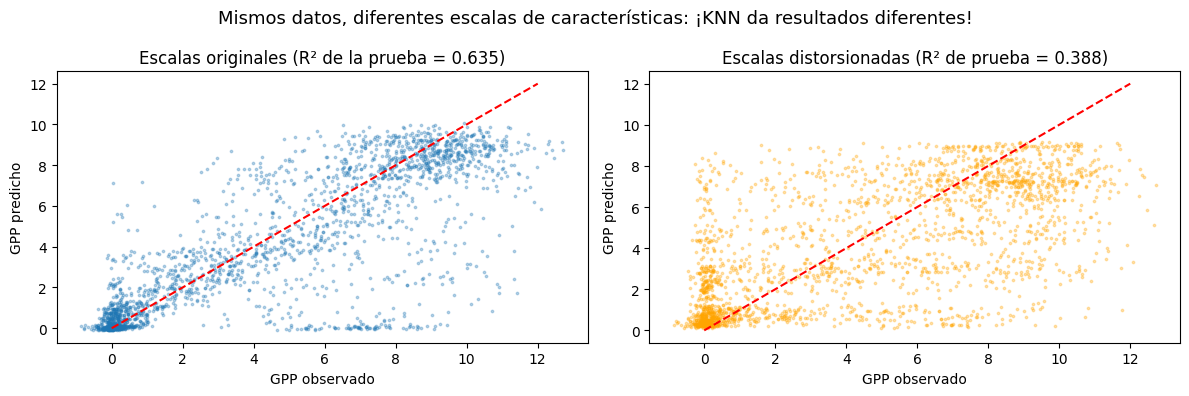

In [ ]:
# ── Distorsionar deliberadamente las escalas ──
X_distorsionada = Ho[["TA_F", "SW_IN_F", "VPD_F"]].copy()
X_distorsionada["VPD_F"] = X_distorsionada["VPD_F"] * 1000 # inflar VPD
X_distorsionada["SW_IN_F"] = X_distorsionada["SW_IN_F"] / 1000 # reducir SW_IN
X_dist = X_distorsionada.values

X_train_d, X_test_d = X_dist[:train_len], X_dist[train_len:]

knn_dist = KNeighborsRegressor(n_neighbors=20)
knn_dist.fit(X_train_d, y_train)
y_pred_dist_test = knn_dist.predict(X_test_d)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, y_pred_raw_test, s=3, alpha=0.3, label='Escalas originales')
axes[0].plot([0, 12], [0, 12], 'r--')
axes[0].set_title(f'Escalas originales (R² de la prueba = {r2_score(y_test, y_pred_raw_test):.3f})')
axes[0].set_xlabel('GPP observado')
axes[0].set_ylabel('GPP predicho')

axes[1].scatter(y_test, y_pred_dist_test, s=3, alpha=0.3, color='orange',
                label='Escalas distorsionadas')
axes[1].plot([0, 12], [0, 12], 'r--')
axes[1].set_title(f'Escalas distorsionadas (R² de prueba = {r2_score(y_test, y_pred_dist_test):.3f})')
axes[1].set_xlabel('GPP observado')
axes[1].set_ylabel('GPP predicho')

plt.suptitle('Mismos datos, diferentes escalas de características: ¡KNN da resultados diferentes!', fontsize=13)
plt.tight_layout()
plt.show()

Las predicciones cambiaron, ¡a pesar de que los datos subyacentes son idénticos! Esto demuestra que **KNN no es invariante a la escala**.

### La solución: normalizar antes del ajuste

k óptimo (CV 5-fold en entrenamiento): k=30  R²_CV=0.748
R² por k: {5: '0.719', 10: '0.731', 15: '0.738', 20: '0.743', 25: '0.747', 30: '0.748'}


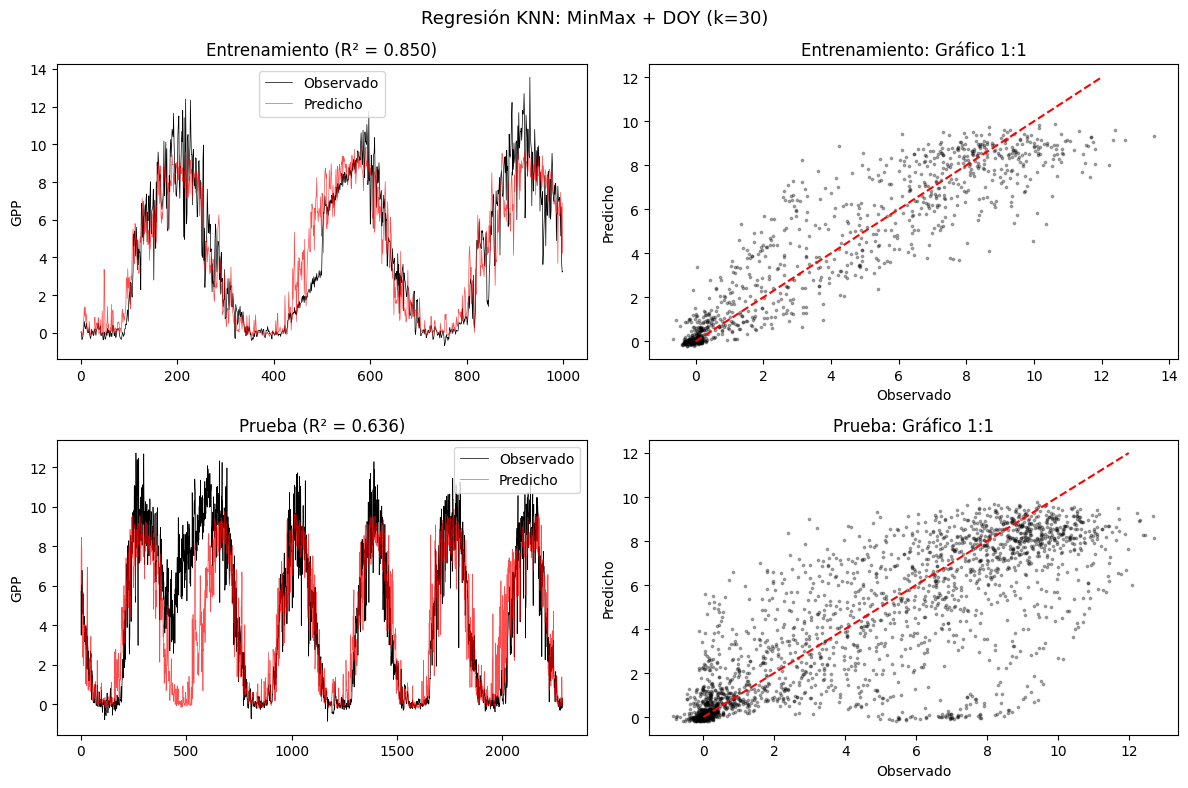


Features: TA_F, SW_IN_F, VPD_F, DOY
Escalado: MinMaxScaler (fit solo en entrenamiento — sin leakage)
k óptimo: 30
Train R²: 0.850
Test  R²: 0.636


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score

# Features: variables meteorológicas + día del año
X = Ho[["TA_F", "SW_IN_F", "VPD_F"]].values
#X = Ho[["TA_F", "SW_IN_F", "VPD_F", "DOY"]].values
#X = Ho[["TA_F", "SW_IN_F", "VPD_F", "DOY_sin", "DOY_cos", "YEAR"]].values

y = Ho["GPP_NT_VUT_REF"].values

# División cronológica
train_len = 1000
X_train, X_test = X[:train_len], X[train_len:]
y_train, y_test = y[:train_len], y[train_len:]

# Escalado correcto: fit SOLO en entrenamiento para evitar leakage
scaler = MinMaxScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

# Elegir k óptimo con validación cruzada sobre datos de entrenamiento
rango_k = [5, 10, 15, 20, 25, 30]
cv_scores = [cross_val_score(KNeighborsRegressor(n_neighbors=k),
                             X_train_sc, y_train, cv=5, scoring='r2').mean()
             for k in rango_k]
mejor_k = rango_k[np.argmax(cv_scores)]
print(f"k óptimo (CV 5-fold en entrenamiento): k={mejor_k}  R²_CV={max(cv_scores):.3f}")
print(f"R² por k: { {k: f'{s:.3f}' for k, s in zip(rango_k, cv_scores)} }")

# Entrenar con k óptimo
knn_scaled = KNeighborsRegressor(n_neighbors=20)
knn_scaled.fit(X_train_sc, y_train)
y_pred_train = knn_scaled.predict(X_train_sc)
y_pred_test  = knn_scaled.predict(X_test_sc)

# Gráfico
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(y_train, 'k-', linewidth=0.5, label='Observado')
axes[0, 0].plot(y_pred_train, 'r-', linewidth=0.5, alpha=0.7, label='Predicho')
axes[0, 0].set_title(f'Entrenamiento (R² = {r2_score(y_train, y_pred_train):.3f})')
axes[0, 0].set_ylabel('GPP')
axes[0, 0].legend()

axes[0, 1].scatter(y_train, y_pred_train, s=3, alpha=0.3, color='k')
axes[0, 1].plot([0, 12], [0, 12], 'r--')
axes[0, 1].set_xlabel('Observado')
axes[0, 1].set_ylabel('Predicho')
axes[0, 1].set_title('Entrenamiento: Gráfico 1:1')

axes[1, 0].plot(y_test, 'k-', linewidth=0.5, label='Observado')
axes[1, 0].plot(y_pred_test, 'r-', linewidth=0.5, alpha=0.7, label='Predicho')
axes[1, 0].set_title(f'Prueba (R² = {r2_score(y_test, y_pred_test):.3f})')
axes[1, 0].set_ylabel('GPP')
axes[1, 0].legend()

axes[1, 1].scatter(y_test, y_pred_test, s=3, alpha=0.3, color='k')
axes[1, 1].plot([0, 12], [0, 12], 'r--')
axes[1, 1].set_xlabel('Observado')
axes[1, 1].set_ylabel('Predicho')
axes[1, 1].set_title('Prueba: Gráfico 1:1')

plt.suptitle(f'Regresión KNN: MinMax + DOY (k={mejor_k})', fontsize=13)
plt.tight_layout()
plt.show()

print(f"\nFeatures: TA_F, SW_IN_F, VPD_F, DOY")
print(f"Escalado: MinMaxScaler (fit solo en entrenamiento — sin leakage)")
print(f"k óptimo: {mejor_k}")
print(f"Train R²: {r2_score(y_train, y_pred_train):.3f}")
print(f"Test  R²: {r2_score(y_test, y_pred_test):.3f}")

Con características normalizadas, las tres variables (temperatura, radiación y VPD) contribuyen por igual al cálculo de la distancia, lo que proporciona vecinos con mayor significado físico y mejores predicciones.

> **Regla general:** Normalice siempre las características antes de usar KNN (y SVM con núcleos RBF). Dos enfoques comunes son el escalado MinMax ($[0, 1]$) y la estandarización de la puntuación z (media=0, desviación estándar=1).

## 8. Ventajas y desventajas de KNN

| Fortalezas | Limitaciones |
|---|---|
| Fácil de entender e implementar | Predicción lenta para conjuntos de datos grandes (debe calcular todas las distancias) |
| Sin fase de entrenamiento: se adapta instantáneamente a nuevos datos | Requiere mucha memoria: almacena todo el conjunto de entrenamiento |
| Funciona tanto para clasificación como para regresión | Sensible a características irrelevantes o redundantes |
| Maneja de forma natural problemas multiclase | Requiere escalado de características |
| No paramétrico: no requiere suposiciones sobre la distribución de datos | El rendimiento se degrada en dimensiones altas ("maldición de la dimensionalidad") |

### La maldición de la dimensionalidad

En espacios de alta dimensionalidad, todos los puntos tienden a estar aproximadamente equidistantes entre sí. Esto significa que el concepto de "vecino más cercano" pierde sentido. Si tiene cientos de características, KNN puede tener dificultades; considere primero la reducción de dimensionalidad (PCA) o utilice un método basado en árboles que se vea menos afectado por características irrelevantes.

## 9. Comparación: KNN vs. Otros Algoritmos

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X_e = StandardScaler().fit_transform(iris.data)
y   = iris.target

clasificadores = {
    "Regresión Logística":   LogisticRegression(max_iter=200),
    "SVM (RBF)":             SVC(kernel="rbf"),
    "Naive Bayes Gaussiano": GaussianNB(),
    "KNN (k=5)":             KNeighborsClassifier(n_neighbors=5),
}

print(f"{'Clasificador':<25}  {'Exactitud media':>16}  {'Desv. std':>10}")
print("-" * 55)
for nombre, clf in clasificadores.items():
    puntuaciones = cross_val_score(clf, X_e, y, cv=5)
    print(f"{nombre:<25}  {puntuaciones.mean():>15.3f}  {puntuaciones.std():>10.3f}")

Clasificador                Exactitud media   Desv. std
-------------------------------------------------------
Regresión Logística                  0.960       0.039
SVM (RBF)                            0.967       0.021
Naive Bayes Gaussiano                0.953       0.027
KNN (k=5)                            0.960       0.025


En el conjunto de datos Iris, pequeño y limpio, los cuatro clasificadores funcionan bien. Las diferencias reales aparecen con datos más complejos y de mayor dimensionalidad. Cada algoritmo tiene su punto óptimo:

- **Regresión logística / SVM lineal:** rápido, interpretable y funciona bien cuando los límites de decisión son aproximadamente lineales.

- **SVM RBF:** potente clasificador no lineal, pero lento para conjuntos de datos grandes y requiere un ajuste preciso de $C$ y $\gamma$.

- **Naive Bayes:** extremadamente rápido, excelente como referencia, pero asume independencia de características.

- **KNN:** simple y no paramétrico, pero lento en la predicción y sensible a la escala y la dimensionalidad.

---
## 🔬 Ejercicio: KNN para Clasificar Tipos de Vegetación Andina

Usando los datos espectrales Landsat sintéticos de cobertura andina:

1. Entrena un clasificador KNN con `k=5` sobre los datos (`X_esp`, `y_esp` del notebook anterior)
2. ¿Cuál es la exactitud de prueba comparada con Naive Bayes?
3. Prueba con `k = [1, 5, 15, 30]` y grafica la exactitud vs. k
4. ¿Por qué KNN necesita escalado y Naive Bayes no?

> **Pista:** Escala siempre con `StandardScaler` antes de usar KNN, y aplica el mismo escalador a los datos de prueba.

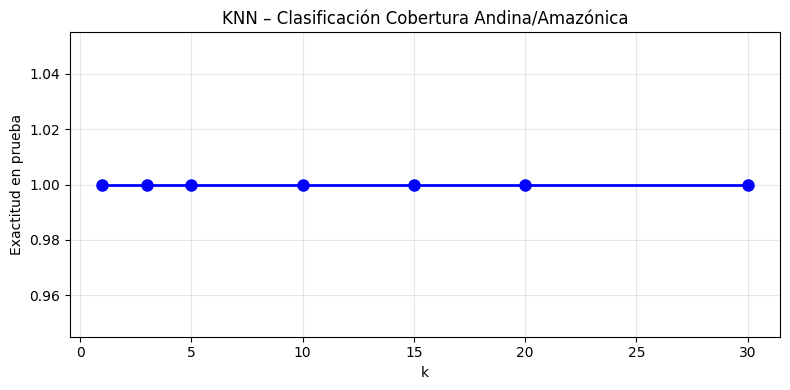

Mejor k: 1 (exactitud = 100.00%)


In [ ]:
# Recrear datos espectrales del notebook Lab7_3
np.random.seed(42)
n_por_clase = 300
agua           = np.random.normal([700, 800, 600, 300, 150, 100], [80]*6, (n_por_clase, 6))
bosque_amazon  = np.random.normal([400, 550, 350, 3800, 1600, 700], [80,80,80,400,300,150], (n_por_clase, 6))
cultivos       = np.random.normal([700, 800, 700, 2600, 2100, 1100], [100]*6, (n_por_clase, 6))
urbano         = np.random.normal([1200, 1300, 1400, 1700, 2400, 2100], [200]*6, (n_por_clase, 6))
pastizal_puna  = np.random.normal([600, 750, 700, 1500, 1200, 800], [100]*6, (n_por_clase, 6))

X_esp = np.vstack([agua, bosque_amazon, cultivos, urbano, pastizal_puna])
y_esp = np.array([0]*n_por_clase + [1]*n_por_clase + [2]*n_por_clase +
                 [3]*n_por_clase + [4]*n_por_clase)

# --- Tu código aquí ---
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

X_tr_e2, X_te_e2, y_tr_e2, y_te_e2 = train_test_split(X_esp, y_esp, test_size=0.25, random_state=42)
esc2 = StandardScaler()
X_tr_es = esc2.fit_transform(X_tr_e2)
X_te_es = esc2.transform(X_te_e2)

# Barrer k
kk = [1, 3, 5, 10, 15, 20, 30]
accs = []
for k in kk:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(X_tr_es, y_tr_e2)
    accs.append(knn_k.score(X_te_es, y_te_e2))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(kk, accs, 'bo-', linewidth=2, markersize=8)
ax.set_xlabel('k')
ax.set_ylabel('Exactitud en prueba')
ax.set_title('KNN – Clasificación Cobertura Andina/Amazónica')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

mejor_k = kk[np.argmax(accs)]
print(f"Mejor k: {mejor_k} (exactitud = {max(accs):.2%})")

---
## Resumen

| Concepto | Conclusión clave |
|----------|------------------|
| Algoritmo KNN | Clasificar/predecir por voto mayoritario (o media) de los $k$ puntos de entrenamiento más cercanos |
| Métrica de distancia | Distancia euclídea por defecto; las características deben estar en la misma escala |
| Elección de $k$ | k pequeño = complejo (sobreajuste); k grande = suave (subajuste) |
| Escalado de características | **Obligatorio** — usar `MinMaxScaler` o `StandardScaler` |
| Clasificación | `KNeighborsClassifier` — voto mayoritario |
| Regresión | `KNeighborsRegressor` — media de los valores de los vecinos |
| Fortalezas | Simple, sin supuestos, funciona para ambas tareas |
| Debilidades | Lento en predicción, consume memoria, sufre en alta dimensión (maldición de la dimensionalidad) |

### Algoritmos vistos hasta ahora

| Lab | Algoritmo | Tipo | Idea clave |
|-----|-----------|------|------------|
| 7_1 | Regresión Lineal / Logística | Regresión / Clasificación | Modelos lineales, minimizar MSE o cross-entropy |
| 7_2 | SVM | Clasificación | Maximizar el margen entre clases |
| 7_3 | Naive Bayes | Clasificación | Teorema de Bayes + supuesto de independencia |
| **7_4** | **KNN** | **Ambos** | **Predecir desde los $k$ ejemplos de entrenamiento más cercanos** |